<a href="https://colab.research.google.com/github/Rony2019-2023/secure-cxr-detection-gbm/blob/main/notebooks/GBM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

print("All libraries imported successfully!")




All libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

DATA_DIR = "/content/drive/MyDrive/Project/Mydataset/FullData"

CLASS_FOLDERS = {
    "Covid-19": 1,
    "Normal": 0,
    "Viral pneumonia": 0
}

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}"
    )

for folder_name in CLASS_FOLDERS:
    folder_path = os.path.join(DATA_DIR, folder_name)

    if not os.path.isdir(folder_path):
        raise FileNotFoundError(
            f"Folder not found: {folder_path}"
        )

    print(f"{folder_name}: Folder found")

print("\nAll dataset folders verified!")









Covid-19: Folder found
Normal: Folder found
Viral pneumonia: Folder found

All dataset folders verified!


In [ ]:

VALID_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".webp")

X_list = []
y_list = []
file_paths = []

for folder_name, label in CLASS_FOLDERS.items():

    folder_path = os.path.join(DATA_DIR, folder_name)

    files = [
        os.path.join(folder_path, filename)
        for filename in os.listdir(folder_path)
        if filename.lower().endswith(VALID_EXTENSIONS)
    ]

    print(f"{folder_name}: {len(files)} images")

    for file_path in files:
        try:
            with Image.open(file_path) as img:
                img = img.convert("L")
                img = img.resize((224, 224))

                image_array = np.asarray(
                    img, dtype=np.float32
                ) / 255.0

                X_list.append(image_array.flatten())
                y_list.append(label)
                file_paths.append(file_path)

        except Exception as error:
            print("Skipping unreadable image:", file_path, error)

X = np.asarray(X_list, dtype=np.float32)
y = np.asarray(y_list, dtype=np.int32)
file_paths = np.asarray(file_paths)

print("\nDataset loaded successfully!")
print("Feature matrix shape:", X.shape)
print("Total images:", len(y))
print("COVID-19 images:", int(np.sum(y == 1)))
print("Non-COVID images:", int(np.sum(y == 0)))

if len(X) == 0 or len(np.unique(y)) != 2:
    raise ValueError(
        "Dataset-এ দুইটি class-এর readable image নিশ্চিত করুন।"
    )


Covid-19: 3618 images


In [ ]:

X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X,
    y,
    file_paths,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

print("\nTraining class distribution:")
print("COVID-19:", int(np.sum(y_train == 1)))
print("Non-COVID:", int(np.sum(y_train == 0)))

print("\nTesting class distribution:")
print("COVID-19:", int(np.sum(y_test == 1)))
print("Non-COVID:", int(np.sum(y_test == 0)))




Training images: 5600
Testing images: 1401

Training class distribution:
COVID-19: 2894
Non-COVID: 2706

Testing class distribution:
COVID-19: 724
Non-COVID: 677


In [ ]:

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

start_time = time.time()

model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds")



Training completed in 6727.37 seconds


In [ ]:

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
sensitivity = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

specificity = (
    tn / (tn + fp) if (tn + fp) > 0 else 0.0
)

roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Sensitivity (Recall)",
        "Specificity",
        "F1-score",
        "ROC-AUC",
        "PR-AUC (Average Precision)",
        "Training Time (seconds)"
    ],
    "Value": [
        accuracy,
        precision,
        sensitivity,
        specificity,
        f1,
        roc_auc,
        pr_auc,
        training_time
    ]
})

print(results.to_string(index=False))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Non-COVID", "COVID-19"],
    zero_division=0
))



                    Metric       Value
                  Accuracy    0.933619
                 Precision    0.923490
      Sensitivity (Recall)    0.950276
               Specificity    0.915805
                  F1-score    0.936692
                   ROC-AUC    0.982697
PR-AUC (Average Precision)    0.982372
   Training Time (seconds) 6727.370639

Classification Report:
              precision    recall  f1-score   support

   Non-COVID       0.95      0.92      0.93       677
    COVID-19       0.92      0.95      0.94       724

    accuracy                           0.93      1401
   macro avg       0.93      0.93      0.93      1401
weighted avg       0.93      0.93      0.93      1401



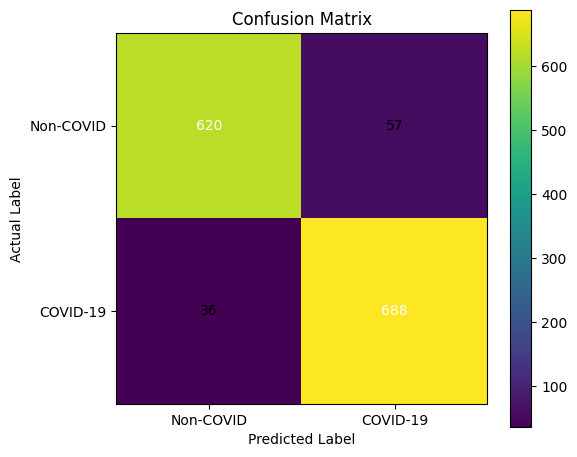

TN = 620
FP = 57
FN = 36
TP = 688


In [ ]:

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["Non-COVID", "COVID-19"])
plt.yticks([0, 1], ["Non-COVID", "COVID-19"])
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

threshold = cm.max() / 2 if cm.max() > 0 else 0

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()
plt.show()

print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")



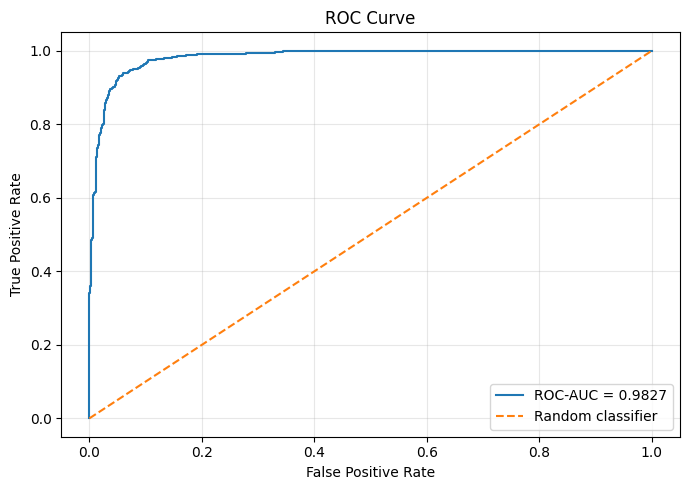

In [ ]:

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], "--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


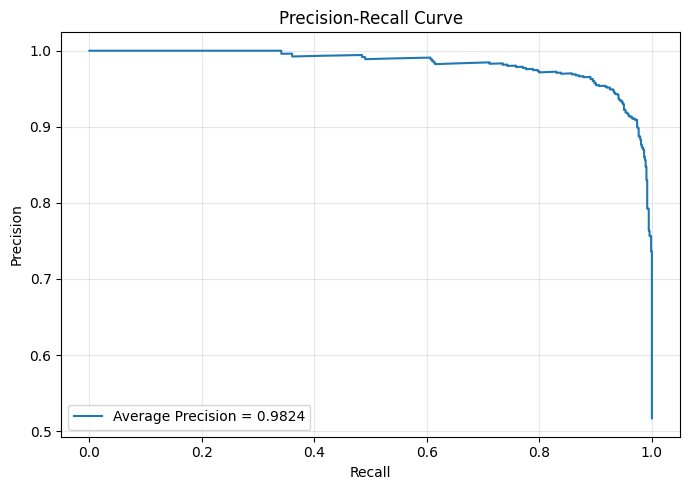

In [ ]:

pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_test, y_prob
)

plt.figure(figsize=(7, 5))
plt.plot(
    pr_recall,
    pr_precision,
    label=f"Average Precision = {pr_auc:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



In [ ]:

RESULT_DIR = "/content/drive/MyDrive/Project/Results"
os.makedirs(RESULT_DIR, exist_ok=True)

results.to_csv(
    os.path.join(RESULT_DIR, "gradient_boosting_metrics.csv"),
    index=False
)

predictions = pd.DataFrame({
    "Image_Path": paths_test,
    "True_Label": y_test,
    "Predicted_Label": y_pred,
    "COVID_Probability": y_prob
})

predictions.to_csv(
    os.path.join(RESULT_DIR, "test_predictions.csv"),
    index=False
)

print("Results saved successfully!")
print("Google Drive folder:", RESULT_DIR)



Results saved successfully!
Google Drive folder: /content/drive/MyDrive/Project/Results
